# FairAge results

Compare five DeiT-Tiny models using published CSVs. The notebook runs without loading any model weights.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from fairage.data import AGE_CLASSES, RACE_GROUPS
from fairage.plots import (plot_age_f1, plot_age_metrics, plot_age_race_support,
                          plot_confusion_matrix, plot_learning_curves, plot_loss_curves,
                          plot_model_comparison, plot_training_efficiency)

ROOT = Path.cwd()
while not (ROOT / "configs/baseline.yaml").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open inside the FairAge checkout")
    ROOT = ROOT.parent
PUBLISHED = ROOT / "results/published"
CHECKPOINT, SPLIT = "best", "development"
SAVE_FIGURES = False
OUT = ROOT / "results/simplified/notebook-analysis"


## 1. Selected checkpoints

`models.csv` lists each model’s selected epoch and settings. Selection used BF16 development macro-F1. The saved checkpoint evaluations use FP32.


In [2]:
published = {name: pd.read_csv(PUBLISHED / f"{name}.csv") for name in (
    "models", "histories", "evaluations", "per_age", "confusion", "age_race",
    "optuna_studies", "optuna_trials", "dataset_counts",
)}
models = published["models"].set_index("run")
RUNS = models.index.tolist()
history = published["histories"]
if CHECKPOINT != "best" or SPLIT not in ("development", "holdout"):
    raise ValueError("The published bundle contains best development/holdout evaluations only")
tables = {
    "metrics": published["evaluations"].query("split == @SPLIT").copy(),
    "by_age": published["per_age"].query("split == @SPLIT").copy(),
    "by_age_race": published["age_race"].query("split == @SPLIT").copy(),
}
metrics = tables["metrics"].set_index("run")
if (metrics.index.tolist() != RUNS or not metrics.epoch.equals(models.selected_epoch)
        or not metrics.evaluation_precision.eq("fp32").all()
        or not history.training_precision.eq("bf16").all()):
    raise ValueError("Published model identity, checkpoint or precision changed")
display(tables["metrics"])


,run,checkpoint,epoch,split,evaluation_precision,support,loss,accuracy,macro_f1,balanced_accuracy,within_one_bin_accuracy,mean_absolute_bin_index_error,mean_max_probability,ece_10,ece_15,wrong_count,wrong_above_90
0,lean-scratch-s4531,best,28,development,fp32,8645,1.267930,0.481434,0.445595,0.437320,0.883401,0.676345,0.551192,0.069767,0.069767,4483,43
2,lean-pretrained-s4531,best,44,development,fp32,8645,5.321977,0.544130,0.529039,0.512191,0.937883,0.531868,0.971189,0.427201,0.427201,3941,3493
4,lean-frozen-s4531,best,36,development,fp32,8645,1.503569,0.392366,0.312483,0.295743,0.776981,0.917178,0.390004,0.007734,0.009614,5253,1
6,optuna-scratch-trial-0011,best,55,development,fp32,8645,1.188767,0.518681,0.499418,0.486610,0.910237,0.597455,0.535955,0.017648,0.018049,4161,4
8,optuna-pretrained-trial-0128,best,9,development,fp32,8645,1.104370,0.555813,0.554338,0.545304,0.948525,0.504222,0.636171,0.080872,0.081106,3840,51


## 2. Learning curves and timing

Solid lines show training and dashed lines show development. Stars mark the earliest epoch with the best development macro-F1. Timing is per epoch. Set `SAVE_FIGURES = True` to export selected plots.


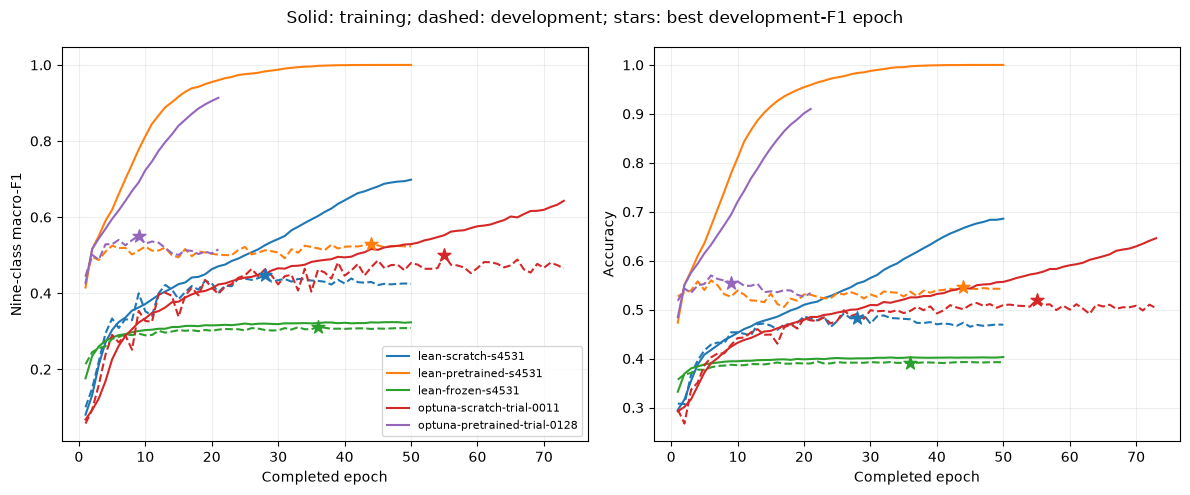

In [3]:
if not history.empty:
    figure, axes = plot_learning_curves(history, save=SAVE_FIGURES,
                                         save_path=OUT / "learning_curves.png")

    plt.show()


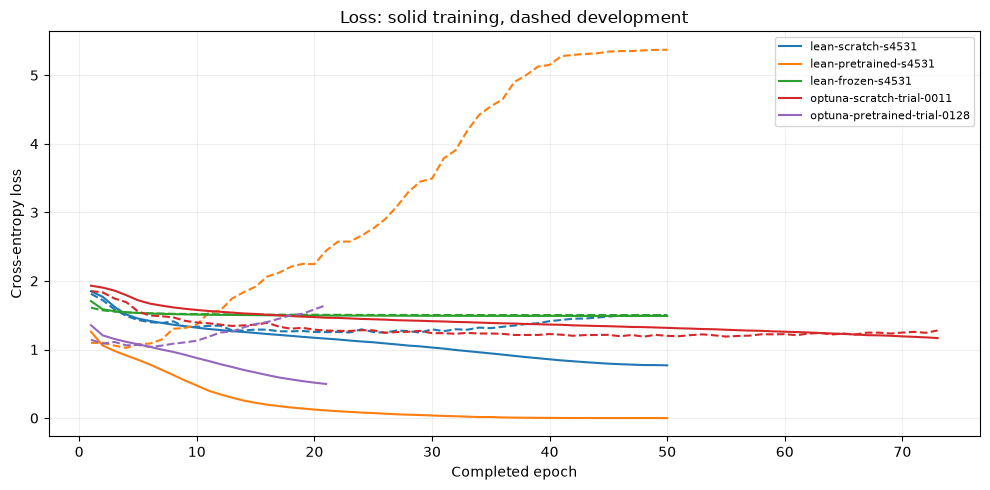

In [4]:
if not history.empty:
    figure, axis = plot_loss_curves(history, save=SAVE_FIGURES,
                                    save_path=OUT / "loss_curves.png")

    plt.show()


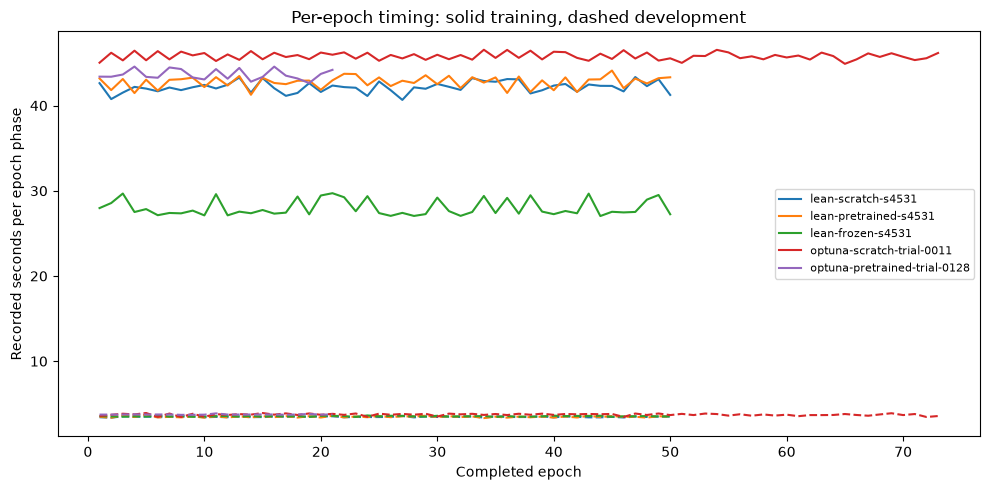

In [5]:
if not history.empty:
    figure, axis = plot_training_efficiency(history, save=SAVE_FIGURES,
                                            save_path=OUT / "epoch_timing.png")

    plt.show()


## 3. Inspect one checkpoint

Confusion matrix rows represent the labeled age categories. Normalized rows divide counts by the number of images in that category. The CSVs include confidence and calibration summaries.


,run,checkpoint,epoch,split,evaluation_precision,age,support,precision,recall,f1
0,lean-scratch-s4531,best,28,development,fp32,0-2,179,0.669421,0.452514,0.540000
1,lean-scratch-s4531,best,28,development,fp32,3-9,1032,0.695167,0.724806,0.709677
2,lean-scratch-s4531,best,28,development,fp32,10-19,905,0.474201,0.213260,0.294207
3,lean-scratch-s4531,best,28,development,fp32,20-29,2555,0.534393,0.605088,0.567548
4,lean-scratch-s4531,best,28,development,fp32,30-39,1921,0.395887,0.480999,0.434313
5,lean-scratch-s4531,best,28,development,fp32,40-49,1071,0.356627,0.276377,0.311415
6,lean-scratch-s4531,best,28,development,fp32,50-59,621,0.385762,0.375201,0.380408
7,lean-scratch-s4531,best,28,development,fp32,60-69,277,0.371025,0.379061,0.375000
8,lean-scratch-s4531,best,28,development,fp32,more than 70,84,0.371134,0.428571,0.397790


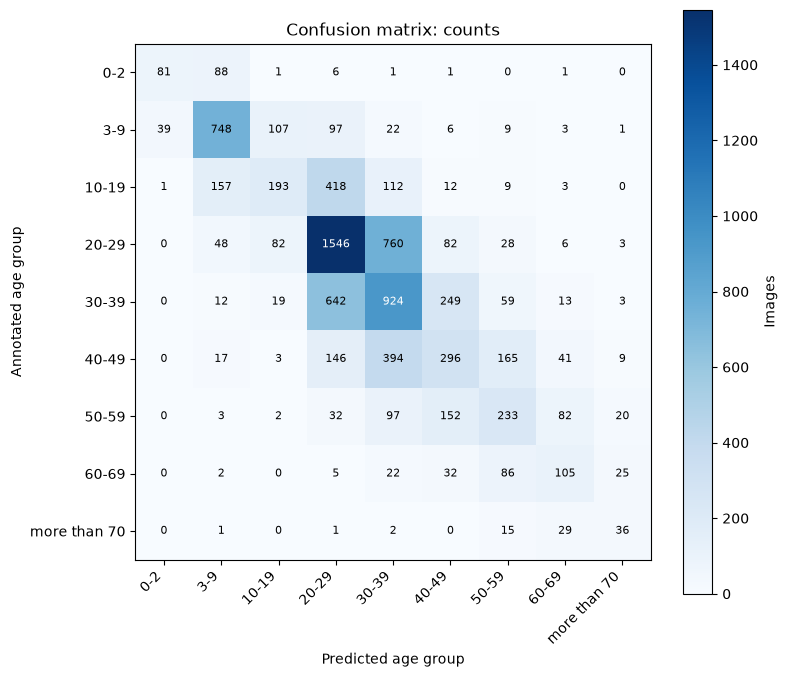

In [6]:
SELECTED_RUN = RUNS[0]
selected = {
    "by_age": tables["by_age"].query("run == @SELECTED_RUN").copy(),
    "by_age_race": tables["by_age_race"].query("run == @SELECTED_RUN").copy(),
}
selected_confusion = published["confusion"].query("run == @SELECTED_RUN and split == @SPLIT")
selected["confusion"] = selected_confusion.pivot(
    index="true_age", columns="predicted_age", values="count"
).reindex(index=AGE_CLASSES, columns=AGE_CLASSES)
display(selected["by_age"])
figure, axis = plot_confusion_matrix(selected["confusion"], save=SAVE_FIGURES,
                                     save_path=OUT / "confusion.png")
plt.show()


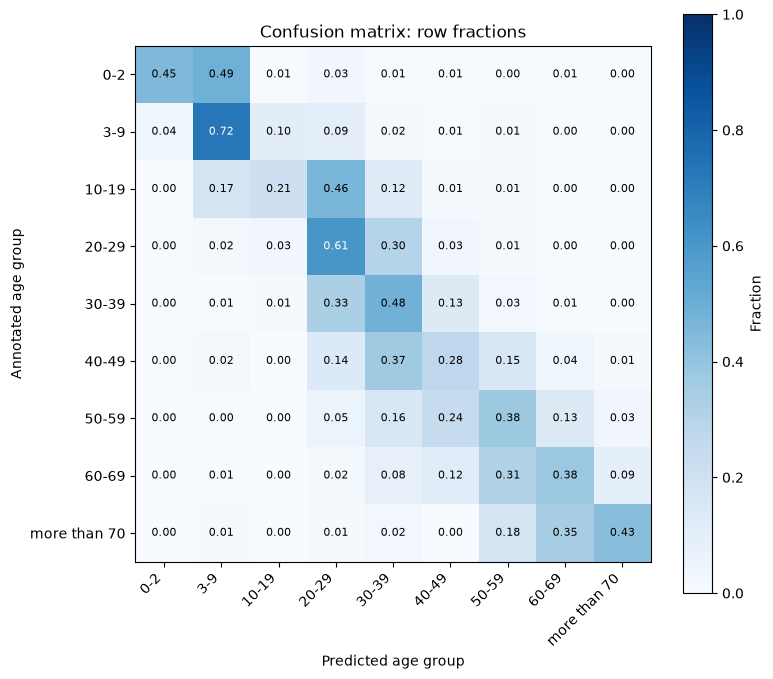

In [7]:
figure, axis = plot_confusion_matrix(selected["confusion"], normalized=True,
                                     save=SAVE_FIGURES, save_path=OUT / "confusion_normalized.png")

plt.show()


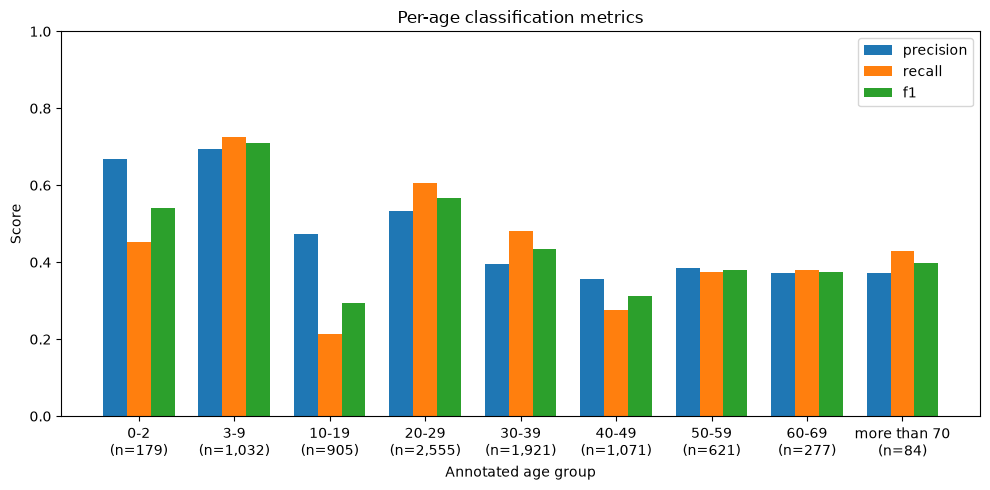

In [8]:
figure, axis = plot_age_metrics(selected["by_age"], save=SAVE_FIGURES,
                                save_path=OUT / "per_age_metrics.png")

plt.show()


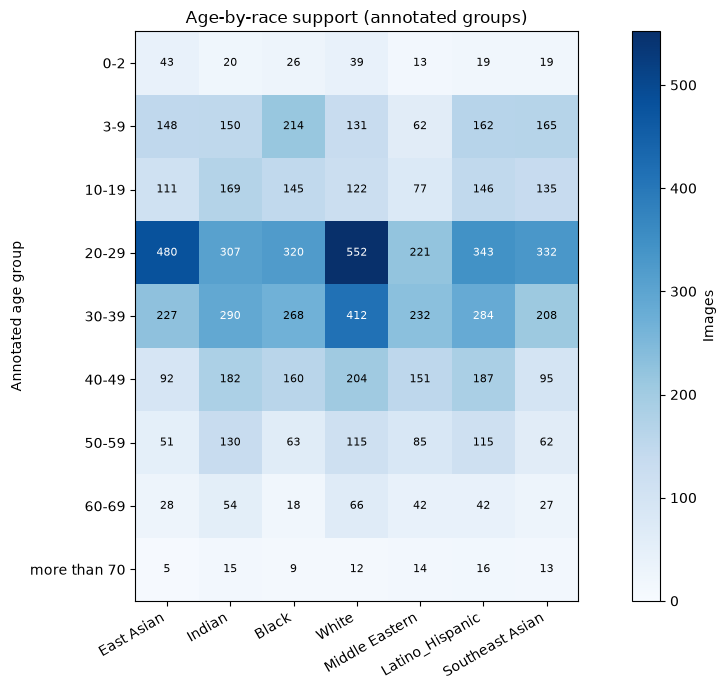

In [9]:
figure, axis = plot_age_race_support(selected["by_age_race"], save=SAVE_FIGURES,
                                     save_path=OUT / "age_race_support.png")

plt.show()


## 4. Compare models

Balanced accuracy averages recall over age categories present in the split. Macro-F1 gives all nine age categories equal weight. Prediction distance is measured in age categories.

The age-by-race table includes all image counts. Accuracy is missing for cells with fewer than 30 images.


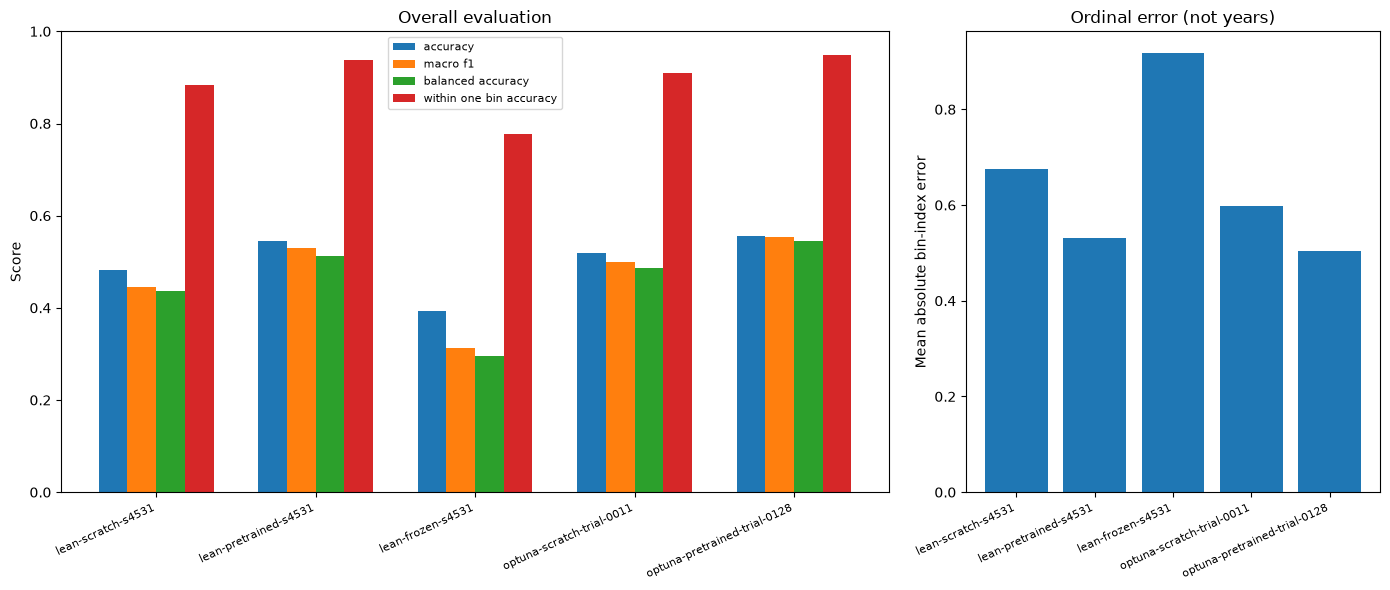

In [10]:
figure, axes = plot_model_comparison(tables["metrics"], save=SAVE_FIGURES,
                                      save_path=OUT / "model_comparison.png")

plt.show()


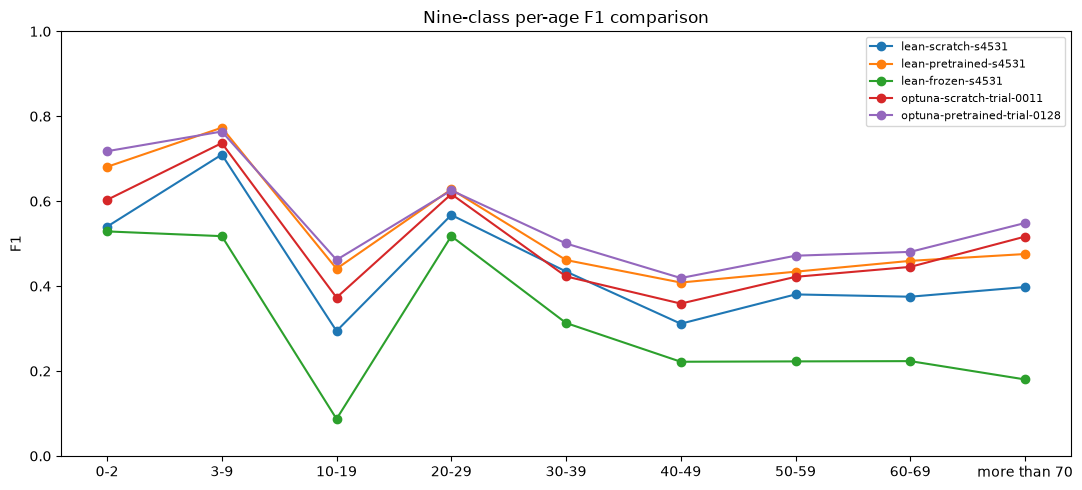

In [11]:
figure, axis = plot_age_f1(tables["by_age"], save=SAVE_FIGURES,
                            save_path=OUT / "per_age_comparison.png")

plt.show()


In [12]:
# Race-wide accuracy/macro-F1 were not published. Suppressed intersections prevent
# faithful reconstruction, so show only the available age/race rows instead.
display(tables["by_age_race"][["run", "race", "age", "support", "accuracy", "suppressed"]])
print("Race-wide metric comparison omitted: unavailable in the public bundle.")


,run,race,age,support,accuracy,suppressed
0,lean-scratch-s4531,East Asian,0-2,43,0.534884,False
1,lean-scratch-s4531,East Asian,3-9,148,0.831081,False
2,lean-scratch-s4531,East Asian,10-19,111,0.108108,False
3,lean-scratch-s4531,East Asian,20-29,480,0.725000,False
4,lean-scratch-s4531,East Asian,30-39,227,0.343612,False
...,...,...,...,...,...,...
562,optuna-pretrained-trial-0128,Southeast Asian,30-39,208,0.500000,False
563,optuna-pretrained-trial-0128,Southeast Asian,40-49,95,0.368421,False
564,optuna-pretrained-trial-0128,Southeast Asian,50-59,62,0.435484,False
565,optuna-pretrained-trial-0128,Southeast Asian,60-69,27,NaN,True


Race-wide metric comparison omitted: unavailable in the public bundle.


## 5. Optuna trials

The trial tables report BF16 development objectives. Pruned trials stopped early, so their scores describe partial runs.


In [13]:
display(published["optuna_studies"])
display(published["optuna_trials"])


,study,experiment,selection_precision,direction,trials,complete,pruned,fail,running,waiting,best_trial,best_value
0,optuna-scratch,scratch,bf16,maximize,51,17,34,0,0,0,11,0.500639
1,optuna-pretrained,pretrained,bf16,maximize,143,117,26,0,0,0,128,0.550741


,study,trial,state,objective,reported_epochs,best_reported_epoch,lr,head_lr_factor,weight_decay,warmup_epochs,schedule,dropout,label_smoothing,augmentation
0,optuna-scratch,0,COMPLETE,0.475170,43,25,0.000212,NaN,0.000112,5,cosine,0.0,0.00,crop
1,optuna-scratch,1,COMPLETE,0.461578,92,74,0.000856,NaN,0.013422,0,cosine,0.1,0.10,crop
2,optuna-scratch,2,COMPLETE,0.447180,44,26,0.000406,NaN,0.000858,5,cosine,0.0,0.10,standard
3,optuna-scratch,3,COMPLETE,0.454960,52,34,0.000037,NaN,0.001574,0,cosine,0.0,0.00,standard
4,optuna-scratch,4,COMPLETE,0.484571,73,55,0.000115,NaN,0.009077,10,constant,0.0,0.10,crop
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189,optuna-pretrained,138,PRUNED,0.521761,10,5,0.000045,10.0,0.018594,0,cosine,0.0,0.05,standard
190,optuna-pretrained,139,COMPLETE,0.546769,21,9,0.000047,10.0,0.031690,0,constant,0.0,0.05,crop
191,optuna-pretrained,140,COMPLETE,0.537239,21,9,0.000039,10.0,0.041691,0,constant,0.0,0.05,crop
192,optuna-pretrained,141,COMPLETE,0.536008,21,9,0.000038,10.0,0.006313,0,cosine,0.0,0.05,crop


## 6. Dataset counts

The publisher-training counts describe the images before the study’s duplicate exclusions.


In [14]:
publisher_counts = published["dataset_counts"].query("population == 'publisher_training'")
for field, order in (("age", AGE_CLASSES), ("race", RACE_GROUPS)):
    distribution = publisher_counts.groupby(field).support.sum().reindex(order).to_frame("count")
    distribution["percent"] = distribution["count"] / publisher_counts.support.sum() * 100
    display(distribution)
display(publisher_counts.pivot(index="age", columns="race", values="support")
        .reindex(index=AGE_CLASSES, columns=RACE_GROUPS))


,count,percent
age,,
0-2,1792,2.065849
3-9,10408,11.998524
10-19,9103,10.494098
20-29,25598,29.509822
30-39,19250,22.191737
40-49,10744,12.385871
50-59,6228,7.179747
60-69,2779,3.203680
more than 70,842,0.970672


,count,percent
race,,
East Asian,12287,14.164668
Indian,12319,14.201559
Black,12233,14.102416
White,16527,19.052615
Middle Eastern,9216,10.624366
Latino_Hispanic,13367,15.409711
Southeast Asian,10795,12.444665


race,East Asian,Indian,Black,White,Middle Eastern,Latino_Hispanic,Southeast Asian
age,,,,,,,
0-2,408,169,279,399,134,189,214
3-9,1736,1530,2072,1237,721,1589,1523
10-19,1176,1529,1518,1148,735,1609,1388
20-29,4765,3077,3171,5221,2323,3531,3510
30-39,2382,2771,2619,4139,2398,2932,2009
40-49,939,1635,1459,2179,1517,1957,1058
50-59,524,984,764,1379,837,1124,616
60-69,270,457,279,676,435,355,307
more than 70,87,167,72,149,116,81,170
